# ADY201m Assignment - Part 2: Data analysis and classification of cardiovascular disease

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme()
df = pd.read_csv("CARDIO_TRAIN.csv")
print(df.shape)
df.head()

(70000, 13)


,ID,AGE,GENDER,HEIGHT,WEIGHT,AP_HI,AP_LO,CHOLESTEROL,GLUC,SMOKE,ALCO,ACTIVE,CARDIO
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,4,47,1,156,56.0,100,60,1,1,0,0,0,0


## 1. Describe data

In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
AGE,70000.0,52.840671,6.766774,29.0,48.00,53.0,58.00,64.0
GENDER,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
HEIGHT,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
WEIGHT,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
AP_HI,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
AP_LO,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
CHOLESTEROL,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
GLUC,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
SMOKE,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [3]:
print(df.isna().sum().sum(), 'missing values;', df.duplicated().sum(), 'duplicates')
df.CARDIO.value_counts()

0 missing values; 0 duplicates


CARDIO
0    35021
1    34979
Name: count, dtype: int64

## 2. Data cleaning
Remove impossible values: `AP_HI < AP_LO`, blood pressure outside a plausible range, and extreme height/weight (1st-99.9th percentile style rules).

In [4]:
before = len(df)
df = df[(df.AP_HI > 0) & (df.AP_LO > 0) & (df.AP_HI >= df.AP_LO)]
df = df[df.AP_HI.between(60, 250) & df.AP_LO.between(30, 200)]
df = df[df.HEIGHT.between(130, 220) & df.WEIGHT.between(30, 200)]
print("removed", before - len(df), "rows ->", len(df), "left")
df.describe().T

removed 1414 rows -> 68586 left


,count,mean,std,min,25%,50%,75%,max
ID,68586.0,49971.834106,28845.142673,0.0,25000.5,50011.0,74859.75,99999.0
AGE,68586.0,52.830155,6.768840,29.0,48.0,53.0,58.00,64.0
GENDER,68586.0,1.348584,0.476526,1.0,1.0,1.0,2.00,2.0
HEIGHT,68586.0,164.437888,7.847127,130.0,159.0,165.0,170.00,207.0
WEIGHT,68586.0,74.113214,14.290474,30.0,65.0,72.0,82.00,200.0
AP_HI,68586.0,126.677325,16.694925,60.0,120.0,120.0,140.00,240.0
AP_LO,68586.0,81.305121,9.466421,30.0,80.0,80.0,90.00,182.0
CHOLESTEROL,68586.0,1.364783,0.678957,1.0,1.0,1.0,2.00,3.0
GLUC,68586.0,1.225804,0.571669,1.0,1.0,1.0,1.00,3.0
SMOKE,68586.0,0.087977,0.283264,0.0,0.0,0.0,0.00,1.0


## 3. Visualisation

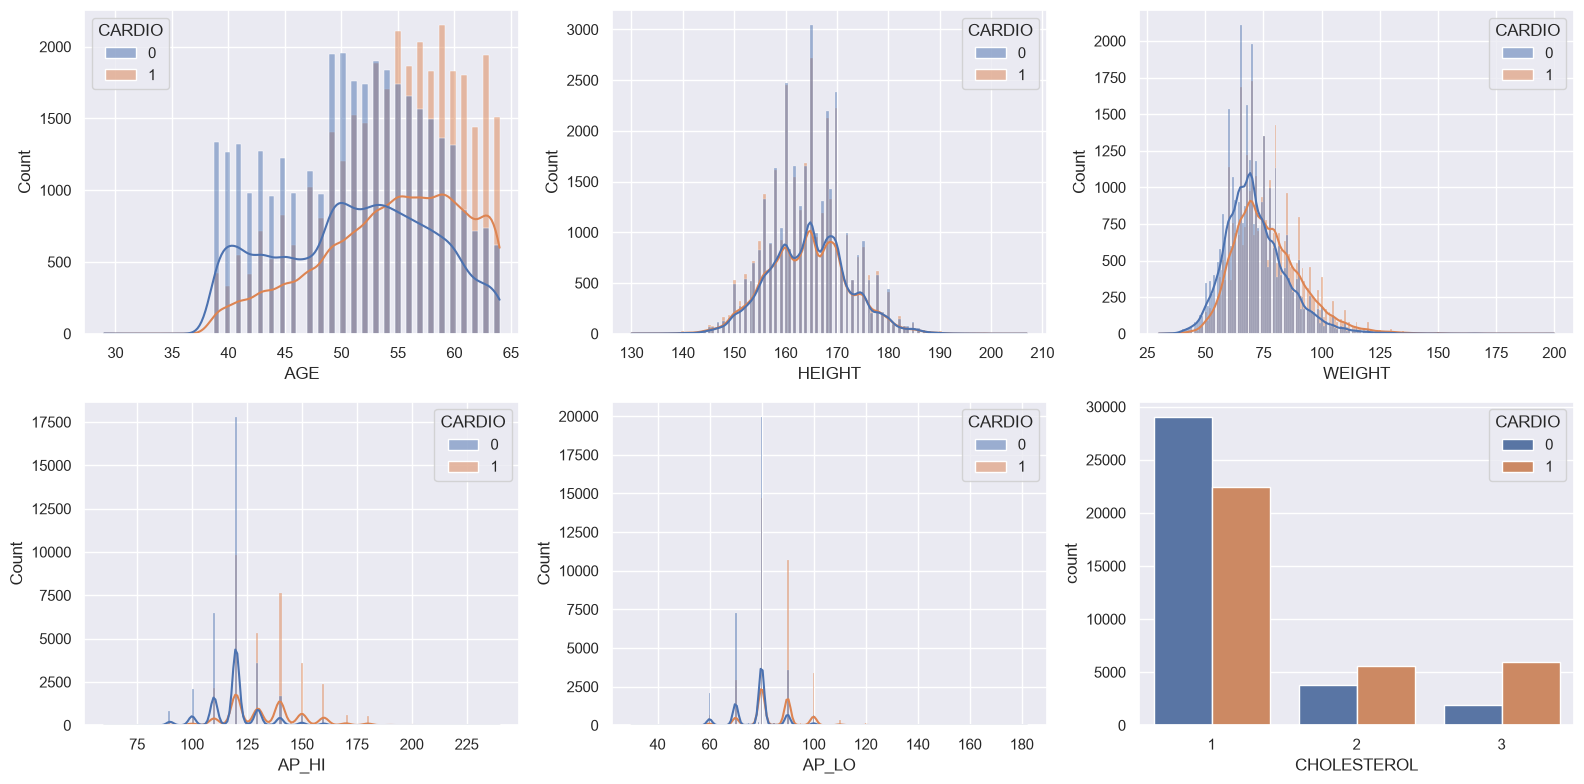

In [5]:
import os; os.makedirs("images", exist_ok=True)
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(ax.ravel(), ["AGE", "HEIGHT", "WEIGHT", "AP_HI", "AP_LO"]):
    sns.histplot(data=df, x=c, hue="CARDIO", kde=True, ax=a)
sns.countplot(data=df, x="CHOLESTEROL", hue="CARDIO", ax=ax[1, 2])
plt.tight_layout(); plt.savefig("images/distributions.png", dpi=120); plt.show()

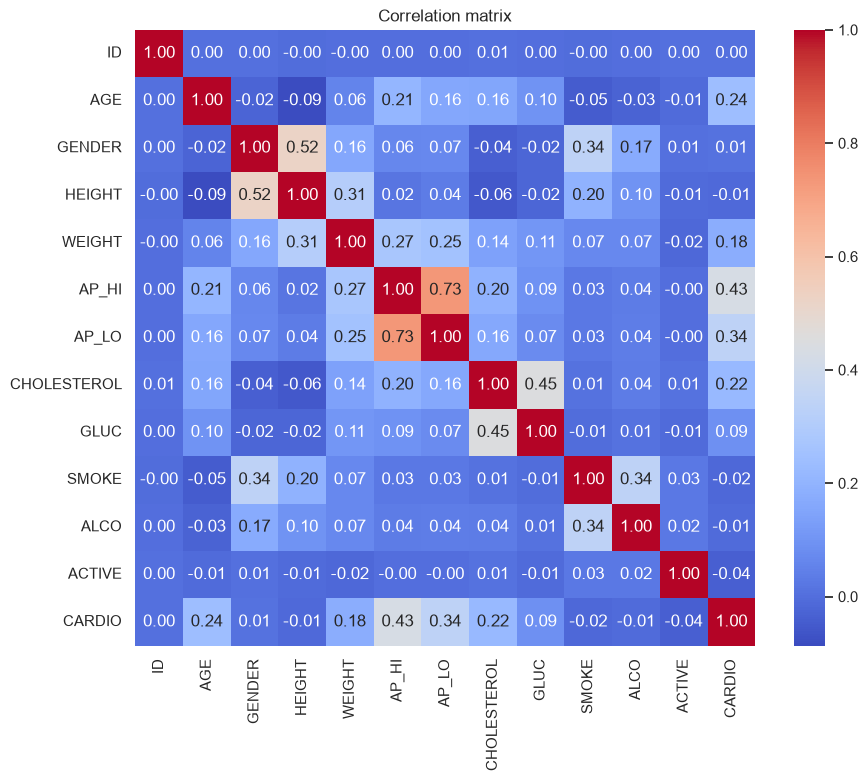

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.savefig("images/correlation.png", dpi=120); plt.show()

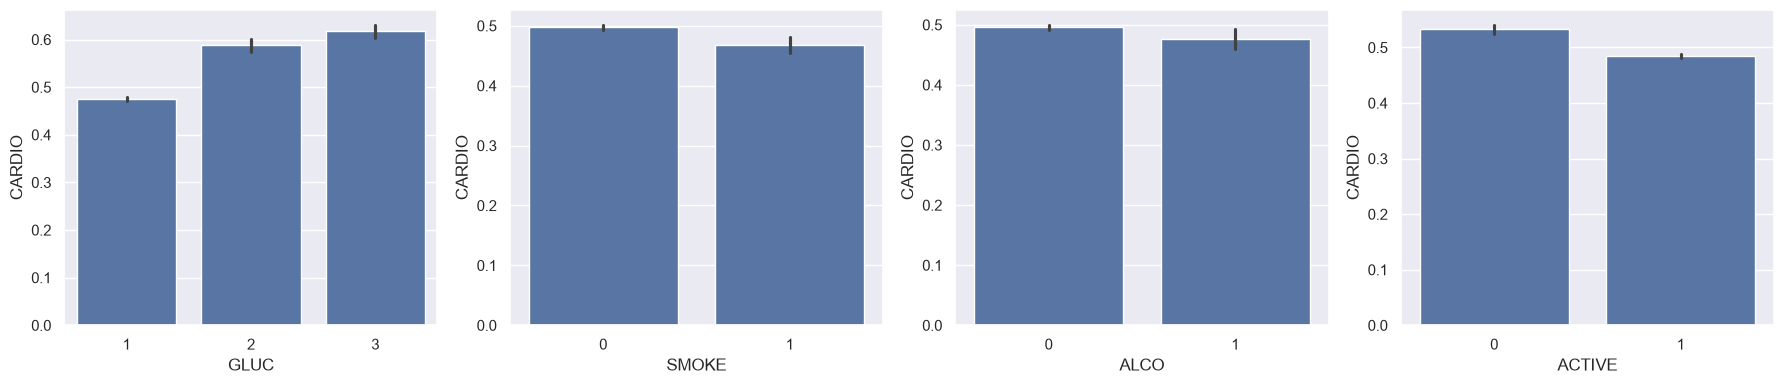

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, c in zip(ax, ["GLUC", "SMOKE", "ALCO", "ACTIVE"]):
    sns.barplot(data=df, x=c, y="CARDIO", ax=a)
plt.tight_layout(); plt.savefig("images/cardio_rate.png", dpi=120); plt.show()

## 4. Statistical tests

In [8]:
from scipy.stats import levene, ttest_ind, pearsonr, chi2_contingency
low = df[df.AGE < df.AGE.mean()].CARDIO; high = df[df.AGE >= df.AGE.mean()].CARDIO
f, p = levene(low, high, center="mean"); print("Levene:", f, p)
t, p2 = ttest_ind(low, high, equal_var=p > 0.05); print("T-test (age groups):", t, p2)
print("Pearson WEIGHT-CARDIO:", pearsonr(df.WEIGHT, df.CARDIO))
chi = chi2_contingency(pd.crosstab(df.ALCO, df.CARDIO), correction=True)
print("Chi2 ALCO-CARDIO: chi2=%.3f p=%.4f" % (chi[0], chi[1]))
print("=> alcohol:", "significant" if chi[1] < 0.05 else "no sufficient evidence (p>=0.05)")

Levene: 280.23774116252946 8.88502255978149e-63
T-test (age groups): -52.388180771697996 0.0
Pearson WEIGHT-CARDIO: PearsonRResult(statistic=np.float64(0.1800089149682103), pvalue=np.float64(0.0))
Chi2 ALCO-CARDIO: chi2=4.914 p=0.0266
=> alcohol: significant


## 5. OLS regression

In [9]:
import statsmodels.api as sm
feats = ["AGE","GENDER","HEIGHT","WEIGHT","AP_HI","AP_LO","CHOLESTEROL","GLUC","SMOKE","ALCO","ACTIVE"]
ols = sm.OLS(df["CARDIO"], sm.add_constant(df[feats])).fit()
ols.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 CARDIO   R-squared:                       0.229
Model:                            OLS   Adj. R-squared:                  0.229
Method:                 Least Squares   F-statistic:                     1848.
Date:                Tue, 06 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:59:20   Log-Likelihood:                -40870.
No. Observations:               68586   AIC:                         8.176e+04
Df Residuals:                   68574   BIC:                         8.187e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.5528      0.045    -34.855      0.000      -1.640      -1.465
AGE             0.0103      0.000     40.128      0.000       0.010       0.011
GENDER         -0.0028      0.004     -0.649      0.517      -0.011       0.006
HEIGHT         -0.0009      0.000     -3.568      0.000      -0.001      -0.000
WEIGHT          0.0022      0.000     17.006      0.000       0.002       0.002
AP_HI           0.0098      0.000     64.897      0.000       0.010       0.010
AP_LO           0.0023      0.000      8.881      0.000       0.002       0.003
CHOLESTEROL     0.0965      0.003     34.018      0.000       0.091       0.102
GLUC           -0.0217      0.003     -6.598      0.000      -0.028      -0.015
SMOKE          -0.0255      0.007     -3.851      0.000      -0.038      -0.013
ALCO           -0.0416      0.008     -5.224      0.000      -0.057      -0.026
ACTIVE         -0.0443      0.004    -10.483      0.000      -0.053      -0.036
==============================================================================
Omnibus:                    31225.053   Durbin-Watson:                   1.983
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3578.919
Skew:                           0.050   Prob(JB):                         0.00
Kurtosis:                       1.885   Cond. No.                     6.41e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.41e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## 6. Standardise, split and model

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
num = ["AGE","HEIGHT","WEIGHT","AP_HI","AP_LO"]; cat = ["GENDER","CHOLESTEROL","GLUC","SMOKE","ALCO","ACTIVE"]
X = np.concatenate([StandardScaler().fit_transform(df[num]), df[cat].values], axis=1)
y = df["CARDIO"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train.shape, X_test.shape

((48010, 11), (20576, 11))

In [11]:
from sklearn.linear_model import RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
                              BaggingClassifier, ExtraTreesClassifier, StackingClassifier)
from sklearn.metrics import accuracy_score

models = {
    "Ridge": RidgeClassifier(alpha=0.0001),
    "RandomForest": RandomForestClassifier(random_state=0),
    "GradientBoosting": GradientBoostingClassifier(random_state=0),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=0),
    "Bagging(KNN)": BaggingClassifier(KNeighborsClassifier(), max_samples=0.5, max_features=0.5, random_state=0),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=100, random_state=0),
    "Stacking": StackingClassifier(
        estimators=[("ridge", RidgeClassifier()), ("knr", KNeighborsClassifier(n_neighbors=20))],
        final_estimator=GradientBoostingClassifier(n_estimators=25, subsample=0.5, min_samples_leaf=25,
                                                   max_features=1, random_state=42)),
}
res = {}
for n, m in models.items():
    m.fit(X_train, y_train)
    res[n] = accuracy_score(y_test, m.predict(X_test))
    print(f"{n:18s} accuracy = {res[n]:.4f}")

Ridge              accuracy = 0.7247


RandomForest       accuracy = 0.7089


GradientBoosting   accuracy = 0.7345


AdaBoost           accuracy = 0.7289


Bagging(KNN)       accuracy = 0.7203


ExtraTrees         accuracy = 0.6980


Stacking           accuracy = 0.7293


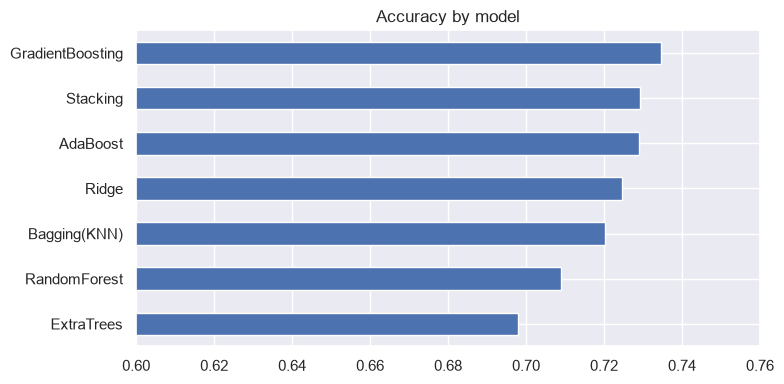

Best model: GradientBoosting 0.7345


In [12]:
r = pd.Series(res).sort_values()
r.plot.barh(figsize=(8, 4), xlim=(0.6, 0.76)); plt.title("Accuracy by model")
plt.tight_layout(); plt.savefig("images/model_accuracy.png", dpi=120); plt.show()
print("Best model:", r.idxmax(), round(r.max(), 4))

## 7. Conclusion
- The target is balanced (~50% ill).
- Blood pressure (AP_HI, AP_LO), age, cholesterol and weight are the strongest factors.
- GradientBoosting gives the best accuracy (~73-74%), slightly better than the Ridge baseline (~72%).
- Alcohol: on the cleaned data the chi-square test gives p ~ 0.027 < 0.05, so there is a statistically significant (but weak) relation. On the raw data (as in the PDF) p ~ 0.055, which is not significant - cleaning changes the conclusion.